# Proximal gradient: Lyapunov discovery

Let $f$ be convex and $L$-smooth, and let $g$ be closed, proper, and convex, on a finite-dimensional Euclidean space. Let $h=f+g$, $L>0$, $R\geq0$, and integer $N\geq1$. The minimizer $x_\star$ satisfies $\|x_0-x_\star\|^2\leq R^2$. Proximal updates and evaluations are well-defined.

$$x_{k+1}=\operatorname{prox}_{g/L}\left(x_k-\frac1L\nabla f(x_k)\right),\qquad k=0,\ldots,N-1.$$

The performance metric is $h(x_N)-h(x_\star)$. The rate was unknown at dispatch.


## Proof Statement

### Theorem

Let $f$ be convex and $L$-smooth, $g$ closed, proper, and convex, and $h=f+g$. Suppose $L>0$, $R\geq0$, $N\geq1$ is an integer, $x_{\star}$ minimizes $h$, and $\|x_{0}-x_{\star}\|^2\leq R^2$. Assume the prescribed proximal updates are well-defined. For
$$x_{k+1}=\operatorname{prox}_{g/L}(x_{k}-\nabla f(x_{k})/L),$$
write $d_{k}=x_{k}-x_{\star}$ and $a_{k}=\nabla f(x_{k})$. Define $V_{0}=0$,
$$
\begin{aligned}
V_{k}={}&-\frac{L}{4N}\|d_{0}\|^2
+\frac{L(N-k)}{(2N-k)^2}\|d_{k}\|^2
-\frac{\langle d_{k},a_{k}\rangle}{2N-k}
+\frac{\|a_{k}-a_{\star}\|^2}{2L(2N-k)}\\
&+\frac{k+1}{2N-k}(f(x_{k})-f(x_{\star}))
+\frac{k}{2N-k}(g(x_{k})-g(x_{\star})),
\qquad 1\leq k<N,
\end{aligned}
$$
and
$$V_{N}=h(x_{N})-h(x_{\star})-\frac{L}{4N}\|d_{0}\|^2.$$
Then $V_{N}\leq\cdots\leq V_{1}\leq V_{0}=0$, including the separate $N=1$ case. Consequently,
$$\boxed{h(x_{N})-h(x_{\star})\leq\frac{L}{4N}\|d_{0}\|^2\leq\frac{LR^2}{4N}.}$$


### Proof outline

The interior potential combines the anchor $-L\|d_{0}\|^2/(4N)$ with
$$
\frac{L(N-k)}{(2N-k)^2}\|d_{k}\|^2
-\frac{\langle d_{k},a_{k}\rangle}{2N-k}
+\frac{\|a_{k}-a_{\star}\|^2}{2L(2N-k)}
+\frac{k+1}{2N-k}(f(x_{k})-f_{\star})
+\frac{k}{2N-k}(g(x_{k})-g_{\star}).
$$
Use $V_{0}=0$ and $V_{N}=h(x_{N})-h_{\star}-L\|d_{0}\|^2/(4N)$ at the endpoints.

Choose $s_{i}=L(x_{i-1}-x_{i})-a_{i-1}\in\partial g(x_{i})$ for $i\geq1$ and $s_{\star}=-a_{\star}\in\partial g(x_{\star})$. Convex interpolation gives
$$I^{f}_{u,v}=f(v)-f(u)+\langle\nabla f(v),u-v\rangle
+\frac{\|\nabla f(u)-\nabla f(v)\|^2}{2L}\leq0,$$
$$I^{g}_{u,v}=g(v)-g(u)+\langle s_{v},u-v\rangle\leq0.$$
The proof never evaluates $g(x_{0})$.

For $1\leq i\leq N$, define
$$\alpha_{i-1}=\frac{i}{2N+1-i},\quad
\beta_{i-1}=\frac{i-1}{2N+1-i},\quad
\delta_{i}=\frac{2N}{(2N-i)(2N+1-i)},$$
$$\gamma_{i}=
\begin{cases}
\frac{2N+1}{(2N-i)(2N+1-i)},&i<N,\\
\frac1{N+1},&i=N.
\end{cases}$$
Set
$$
\begin{aligned}
c_{1,i}&=\frac{N}{(2N+1-i)(2N-i)L},&
u_{1,i}&=\frac{i}{2N}a_{i}+\frac{2N-i}{2N}a_{i-1}-a_{\star},\\
c_{2,i}&=\frac1{2L}\left(
\frac{(i-1)(2N+2)}{(2N-i)(2N+1)}
+\frac{2N}{(2N-i)^2(2N+1)}\right),&
u_{2,i}&=a_{i-1}+s_{i}-\frac{L}{2N+1-i}d_{i-1},\\
c_{3,i}&=\frac{i}{2N+1-i}\frac{2N}{2N+1}\frac1{2L},&
u_{3,i}&=\frac{2N+1}{2N}(a_{i}+s_{i})
-\frac{a_{i-1}+s_{i}}{2N}-\frac{L}{2N-i}d_{i},
\end{aligned}
$$
and $Q_{i}=c_{1,i}\|u_{1,i}\|^2+c_{2,i}\|u_{2,i}\|^2+c_{3,i}\|u_{3,i}\|^2$.
These square families are the declared supplied assistance; their use is justified by the exact local identities below.

For every $i=1,\ldots,N$ the complete increment is
$$
\begin{aligned}
V_{i}-V_{i-1}={}&
\alpha_{i-1}I^{f}_{x_{i-1},x_{i}}
+\mathbf1_{\{i\geq2\}}\beta_{i-1}I^{g}_{x_{i-1},x_{i}}
+\gamma_{i}I^{f}_{x_{\star},x_{i}}
+\delta_{i}I^{g}_{x_{\star},x_{i}}\\
&+\mathbf1_{\{i=1\}}\frac1{2N}I^{f}_{x_{\star},x_{0}}
-Q_{i}.
\end{aligned}
$$
The term involving $I^{g}_{x_{0},x_{1}}$ is absent, not an evaluation multiplied by zero. Exact symbolic checks cover the interior, first step, final step, and $N=1$ separately.

All interpolation multipliers are nonnegative. Since $2N-i\geq N\geq1$, $2N+1-i\geq N+1>0$, and $L>0$, each square coefficient is positive; for $c_{2,1}$ its second summand is strictly positive. Thus every increment is nonpositive. Telescoping yields $V_{N}\leq V_{0}=0$, and the displayed terminal definition and initial radius bound give the claimed rate. No positivity of $V_{k}$ is required.


In [1]:
import sys
from pathlib import Path

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [
    str(repo_root),
    str(notebook_dir),
    str(notebook_dir / "supplementary" / "helpers"),
]

In [2]:
from runtime import configure  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

configure()

In [3]:
import json
import pepflow as pf
import numpy as np
import matplotlib.pyplot as plt

In [4]:
L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
g = pf.ConvexFunction(is_basis=True, tags=["g"])
h = f + g

In [5]:
def make_ctx_pgm(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    h.set_stationary_point("x_star")
    x = pf.Vector(is_basis=True, tags=["x_0"])
    for i in range(N):
        x = g.prox(x - f.grad(x) / L, 1 / L, tag=f"x_{i + 1}")
    f(x)
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_pgm(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(h(ctx[f"x_{N}"]) - h(ctx["x_star"]))
    return ctx, pb, f

## Numerical evidence

N=1: 0.2500000043 (optimal, CLARABEL)
N=2: 0.1249999977 (optimal, CLARABEL)
N=3: 0.0833333328 (optimal, CLARABEL)
N=4: 0.0624999991 (optimal, CLARABEL)
N=5: 0.0499999995 (optimal, CLARABEL)
N=6: 0.0416666662 (optimal, CLARABEL)
N=7: 0.0357142853 (optimal, CLARABEL)
Inverse values: [ 3.99999993  8.00000015 12.00000008 16.00000024 20.0000002  24.00000025
 28.00000036]
Maximum absolute discrepancy: 4.289838206883445e-09


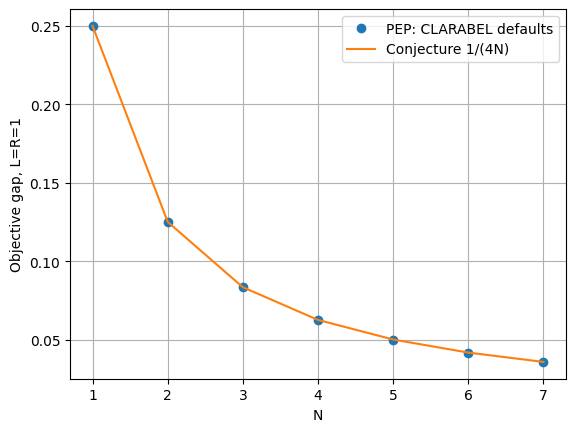

In [6]:
state = json.loads((notebook_dir / "state" / "pgm_b1.json").read_text())
sweep = state["sweep_results"]
horizons = np.array([row["N"] for row in sweep])
values = np.array([row["opt_value"] for row in sweep])
candidate = 1 / (4 * horizons)
for row in sweep:
    print(f"N={row['N']}: {row['opt_value']:.10f} ({row['status']}, {row['solver']})")
print("Inverse values:", 1 / values)
print("Maximum absolute discrepancy:", np.max(np.abs(values - candidate)))
assert np.max(np.abs(values - candidate)) <= 1e-5
assert all(row["status"] == "optimal" for row in sweep)
fig, ax = plt.subplots()
ax.plot(horizons, values, "o", label="PEP: CLARABEL defaults")
ax.plot(horizons, candidate, "-", label="Conjecture 1/(4N)")
ax.set(xlabel="N", ylabel="Objective gap, L=R=1")
ax.legend()
ax.grid(True)
plt.show()

The observed inverse values are approximately $4,8,\ldots,28$. Homogeneity in $L$ and in the squared radius gives the conjecture $LR^2/(4N)$. This is numerical evidence; later blocks must establish the certificate and exact proof.



## Full-PEP certificate: dense and sparse solves

At $N=4$, the dense solve includes every smooth-convex interpolation inequality of $f$ and convex interpolation inequality of $g$. Both solves use CLARABEL defaults. The sparse solve retains only pairs $(x_\star,x_j)$ and $(x_i,x_{i+1})$ for both functions, with their applicable index ranges. Small dense entries alone are not set to zero: a fresh solve under this relaxation supplies all selected duals and the slack matrix together.


In [7]:
import sympy as sp
from pepflow.utils import Comparator

b2 = json.loads((notebook_dir / "state/pgm_b2.json").read_text())
dense = json.loads((notebook_dir / "state/pgm_dense.json").read_text())
print("Dense objective:", dense["opt_value"])
print("Selected objective:", b2["opt_value"])
print("Dense-relaxed gap:", abs(dense["opt_value"] - b2["opt_value"]))
assert abs(dense["opt_value"] - b2["opt_value"]) < 1e-5
print("Basis:", b2["basis_vectors"])
for owner in ("f", "g"):
    active = [
        (name, value)
        for name, value in dense["named_dual_values"].items()
        if name.startswith(owner + ":") and value is not None and value > 1e-6
    ]
    print(
        "Dense active group",
        owner,
        "count",
        len(active),
        "range",
        (min(v for _, v in active), max(v for _, v in active)),
    )
    selected = [
        (name, value)
        for name, value in b2["named_dual_values"].items()
        if name.startswith(owner + ":") and value is not None
    ]
    print("Selected", owner, selected)
print("Dense S eigenvalues:", np.linalg.eigvalsh(dense["S_matrix"]))
print("Selected solver:", b2["certificate_provenance"]["solver"])

Dense objective: 0.062499999067619785
Selected objective: 0.06249999883880585
Dense-relaxed gap: 2.2881393307860876e-10
Basis: ['x_star', 'grad_f(x_star)', 'x_0', 'grad_f(x_0)', 'grad_g(x_1)', 'grad_f(x_1)', 'grad_g(x_2)', 'grad_f(x_2)', 'grad_g(x_3)', 'grad_f(x_3)', 'grad_g(x_4)', 'grad_f(x_4)']
Dense active group f count 30 range (5.411455892081596e-06, 0.507301258841541)
Selected f [('f:x_star,x_0', 0.12500005247782897), ('f:x_star,x_1', 0.16071565747002725), ('f:x_star,x_2', 0.21428742795543826), ('f:x_star,x_3', 0.29999886259289454), ('f:x_star,x_4', 0.19999801570087924), ('f:x_0,x_1', 0.12500005247782917), ('f:x_1,x_2', 0.2857157067084429), ('f:x_2,x_3', 0.5000031314244675), ('f:x_3,x_4', 0.8000019907779483)]
Dense active group g count 16 range (0.02437831623960572, 0.4836133487723516)
Selected g [('g:x_star,x_1', 0.14285465744382342), ('g:x_star,x_2', 0.19048013709241893), ('g:x_star,x_3', 0.26666834785004034), ('g:x_star,x_4', 0.39999687057137245), ('g:x_1,x_2', 0.1428546574438

### Candidate multipliers and supplied SOS

Rational inspection of the selected multipliers gives forward weights
$$\alpha_i=\frac{i+1}{2N-i}\quad(0\leq i<N),\qquad
\beta_i=\frac{i}{2N-i}\quad(1\leq i<N).$$
The outgoing minimizer weights are the consecutive differences of these flows, with terminal flow one; the code includes both endpoints explicitly. The initial multiplier is $L/(4N)$ (the code below evaluates $L=1$).

The SOS below is the supplied candidate, implemented with exact rational coefficients. The certificate uses it with overall scale **one**. Its coefficients are positive for $1\leq i\leq N$, $N\geq1$, and $L>0$: all denominators are positive and the second family's strictly positive second summand covers $i=1$.

The formulas remain candidates for arbitrary horizons. An exact identity at this selected horizon is a fixed-sample check.


In [8]:
def inventory(ctx, pb):
    entries = [(c, "initial", None, None) for c in pb.init_conditions]
    for owner in ctx.func_to_triplets:
        owner.get_interpolation_constraints(ctx)
        groups = ctx.get_constraint_data(owner)
        entries.extend(
            (c, "interpolation", str(owner), str(group))
            for group, constraints in groups.sc_dict.items()
            for c in constraints
        )
        assert not groups.psd_dict
    assert len({c.name for c, *_ in entries}) == len(entries)
    return entries


def residual(c):
    q = c.lhs - c.rhs
    return -q if c.cmp in (Comparator.GE, Comparator.SEQ) else q


def maxabs(a):
    return float(np.max(np.abs(np.asarray(a, dtype=float)), initial=0))


def aid_terms(ctx, n):
    """Exact supplied aid, with original normalization."""
    n = sp.S(n)
    astar = f.grad(ctx["x_star"])
    terms = []
    for ii in range(1, int(n) + 1):
        i = sp.S(ii)
        xp, x = ctx[f"x_{ii - 1}"], ctx[f"x_{ii}"]
        ap, a = f.grad(xp), f.grad(x)
        si = L * (xp - x) - ap
        c1 = n / ((2 * n + 1 - i) * (2 * n - i) * L)
        u1 = i / (2 * n) * a + (2 * n - i) / (2 * n) * ap - astar
        c2 = (
            (i - 1) / (2 * n - i) * (2 * n + 2) / (2 * n + 1)
            + 2 * n / ((2 * n - i) ** 2 * (2 * n + 1))
        ) / (2 * L)
        u2 = ap + si - L / (2 * n + 1 - i) * (xp - ctx["x_star"])
        c3 = i / (2 * n + 1 - i) * 2 * n / (2 * n + 1) / (2 * L)
        u3 = (
            (2 * n + 1) / (2 * n) * (a + si)
            - (ap + si) / (2 * n)
            - L / (2 * n - i) * (x - ctx["x_star"])
        )
        terms.extend([(ii, 1, c1, u1), (ii, 2, c2, u2), (ii, 3, c3, u3)])
    return terms


def lambda_candidate(name, n):
    n = sp.S(n)
    if name == "initial_condition":
        return sp.S.One / (4 * n)
    owner, pair = name.split(":")
    a, b = pair.split(",")
    if a == "x_star":
        j = int(b[2:])
        if owner == "g":
            return 2 * n / ((2 * n - j) * (2 * n + 1 - j))
        if j == 0:
            return sp.S.One / (2 * n)
        if j == n:
            return sp.S.One / (n + 1)
        return (2 * n + 1) / ((2 * n - j) * (2 * n + 1 - j))
    if b != "x_star" and int(b[2:]) == int(a[2:]) + 1:
        i = int(a[2:])
        return (i + 1) / (2 * n - i) if owner == "f" else i / (2 * n - i)
    return sp.S.Zero


def verify(ctx, pb, data, dense_value):
    pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
    matrix = np.asarray(data["S_matrix"])
    basis = ctx.basis_vectors()
    snum = sum(
        (
            float(matrix[i, j]) * basis[i] * basis[j]
            for i, j in np.ndindex(matrix.shape)
        ),
        pf.Scalar.zero(),
    )
    weighted = pf.Scalar.zero()
    entries = inventory(ctx, pb)
    assert set(data["named_dual_values"]) == {c.name for c, *_ in entries}
    for c, *_ in entries:
        v = data["named_dual_values"][c.name]
        if v is not None:
            weighted += v * residual(c)
    diff = pm.eval_scalar(pb.performance_metric - data["opt_value"] - weighted + snum)
    checks = dict(
        identity_gram_max_abs=maxabs(diff.inner_prod_coords),
        identity_func_max_abs=maxabs(diff.func_coords),
        identity_offset_abs=maxabs(diff.offset),
        dense_relaxed_gap=abs(data["opt_value"] - dense_value),
        minimum_scalar_inequality_dual=min(
            v for v in data["named_dual_values"].values() if v is not None
        ),
        minimum_S_eigenvalue=float(np.linalg.eigvalsh(matrix).min()),
        minimum_matrix_inequality_eigenvalue=0.0,
    )
    assert (
        max(
            checks[k]
            for k in (
                "identity_gram_max_abs",
                "identity_func_max_abs",
                "identity_offset_abs",
                "dense_relaxed_gap",
            )
        )
        <= 1e-5
    ), checks
    assert checks["minimum_scalar_inequality_dual"] >= -1e-6
    assert checks["minimum_S_eigenvalue"] >= -1e-6
    assert data["certificate_provenance"]["solver_status"] == "optimal"
    assert np.allclose(matrix, matrix.T, atol=1e-6, rtol=0)
    return checks, diff

In [9]:
n = b2["N_verify"]
ctx, pb, _ = get_pep_setup(n, {"L": sp.S.One, "R": sp.S.One})
pb.set_relaxed_constraints(b2["relaxed_constraints"])
assert [str(v) for v in ctx.basis_vectors()] == b2["basis_vectors"]
assert [str(v) for v in ctx.basis_scalars()] == b2["basis_scalars"]
checks, numerical_residual = verify(ctx, pb, b2, dense["opt_value"])
pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
for owner, first in (("f", 0), ("g", 1)):
    labels = ["x_star"] + [f"x_{j}" for j in range(first, n + 1)]
    candidate_matrix = np.array(
        [
            [
                lambda_candidate(f"{owner}:{a},{b}", n) if a != b else sp.S.Zero
                for b in labels
            ]
            for a in labels
        ],
        dtype=object,
    )
    print("Candidate lambda", owner)
    pf.pprint_labeled_matrix(pf.MatrixWithNames(candidate_matrix, labels, labels))
fit_errors = [
    abs(float(lambda_candidate(name, n)) - value)
    for name, value in b2["named_dual_values"].items()
    if value is not None
]
assert max(fit_errors) <= 1e-4
print("Candidate multiplier max error:", max(fit_errors))

Candidate lambda f


<IPython.core.display.Math object>

Candidate lambda g


<IPython.core.display.Math object>

Candidate multiplier max error: 3.946616228461819e-06


### Slack decomposition and complete certificate checks

Normalize every interpolation inequality as $R\leq0$. The primal dual certificate identity is
$$h(x_N)-h(x_\star)-B-\sum_c d_cR_c+S=0.$$
The sum includes the initial residual $\|x_0-x_\star\|^2-R^2$ and every active interpolation group. The checks cover Gram coefficients, function coefficients, constants, multiplier signs, slack PSD, and the preserved bound. No multiplier is drawn from a different solve.


In [10]:
terms = aid_terms(ctx, n)
aid = sum((c * u**2 for _, _, c, u in terms), pf.Scalar.zero())
D = np.diag([float(pm.eval_scalar(c)) for _, _, c, _ in terms])
E = np.array([pm.eval_vector(u).coords for _, _, _, u in terms], dtype=float)
S_candidate = E.T @ D @ E
assert np.all(np.diag(D) > 0)
assert np.allclose(S_candidate, b2["S_matrix"], atol=1e-4, rtol=1e-5)
ae = pm.eval_scalar(aid)
assert maxabs(ae.func_coords) == 0 and maxabs(ae.offset) == 0
print("Direct S reconstruction error:", maxabs(S_candidate - np.array(b2["S_matrix"])))
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(S_candidate, b2["basis_vectors"], b2["basis_vectors"])
)
weighted = pf.Scalar.zero()
exact_weighted = pf.Scalar.zero()
for c, *_ in inventory(ctx, pb):
    value = b2["named_dual_values"][c.name]
    if value is not None:
        weighted += value * residual(c)
    else:
        assert lambda_candidate(c.name, n) == 0
    exact_weighted += lambda_candidate(c.name, n) * residual(c)
aid_residual = pm.eval_scalar(pb.performance_metric - b2["opt_value"] - weighted + aid)
print("Saved S complete numerical residuals:", checks)
print(
    "Using direct SOS: Gram, function, offset:",
    maxabs(aid_residual.inner_prod_coords),
    maxabs(aid_residual.func_coords),
    maxabs(aid_residual.offset),
)
assert (
    max(
        maxabs(aid_residual.inner_prod_coords),
        maxabs(aid_residual.func_coords),
        maxabs(aid_residual.offset),
    )
    <= 1e-5
)
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        np.asarray(aid_residual.inner_prod_coords, dtype=float),
        b2["basis_vectors"],
        b2["basis_vectors"],
    )
)
exact_residual = pm.eval_scalar(
    pb.performance_metric - sp.Rational(1, 4 * n) - exact_weighted + aid,
    sympy_mode=True,
)
assert all(
    sp.simplify(v) == 0
    for v in [
        *exact_residual.inner_prod_coords.flat,
        *exact_residual.func_coords.flat,
        exact_residual.offset,
    ]
)
print("Exact candidate identity at N =", n, ": all coordinates zero")
print(
    "Numerical certificate verified; analytic full-PEP and Lyapunov proof remain pending."
)

Direct S reconstruction error:

 3.1354779496117757e-06


<IPython.core.display.Math object>

Saved S complete numerical residuals: {'identity_gram_max_abs': 5.288625870569774e-09, 'identity_func_max_abs': 1.6197068353207555e-08, 'identity_offset_abs': 3.1656414087311013e-09, 'dense_relaxed_gap': 2.2881393307860876e-10, 'minimum_scalar_inequality_dual': 0.06250000200444726, 'minimum_S_eigenvalue': 2.1987056779571475e-09, 'minimum_matrix_inequality_eigenvalue': 0.0}
Using direct SOS: Gram, function, offset: 3.1391468687802515e-06 1.6197068353207555e-08 3.1656414087311013e-09


<IPython.core.display.Math object>

Exact candidate identity at N = 4 : all coordinates zero
Numerical certificate verified; analytic full-PEP and Lyapunov proof remain pending.


### Initial formula search and B2 conclusion

The dense certificate was inspected across both interpolation families. The consecutive/minimizer sparse recipe preserved its bound. Rational approximations and flow differences supplied multiplier candidates, compared against every active selected multiplier. The supplied three-family SOS matches the same selected slack; its exact candidate identity also vanishes in every coordinate at $N=4$.

This completes the initial formula search and numerical certificate gate. The all-horizon analytic identity and Lyapunov proof are unresolved.



## Lyapunov partial sums

Write $I^f_{a,b}\leq0$ and $I^g_{a,b}\leq0$ for the normalized interpolation residuals attached to the named directed pairs. Let $Q_i$ denote the PSD numerical slack pieces obtained by transporting the supplied factor coordinates to the saved slack matrix (with the nullspace remainder included at the final step). Starting from $V_0=0$, accumulate all minimizer pairs through $x_k$, all forward pairs through $x_k$, and subtract $Q_1,\ldots,Q_k$.

For $1\leq k<N$,
$$V_{k+1}-V_k=
 \lambda^f_{\star,k+1}I^f_{\star,k+1}
+\lambda^g_{\star,k+1}I^g_{\star,k+1}
+\lambda^f_{k,k+1}I^f_{k,k+1}
+\lambda^g_{k,k+1}I^g_{k,k+1}-Q_{k+1}.$$
At the first step also include $\lambda^f_{\star,0}I^f_{\star,0}$; there is no $g$ forward pair from $x_0$. Every multiplier is nonnegative and every $Q_i$ is nonnegative, so the increments have the nonincreasing sign.

The initial distance constraint stays in the boundary argument. All interpolation terms and all square pieces are accumulated: there are no terminal leftovers. The terminal relation is numerically
$$V_N=h(x_N)-h(x_\star)-B-\tau(\|x_0-x_\star\|^2-R^2),$$
with the full constant-coordinate residual retained. This fixed-sample construction is not yet the analytic theorem.


In [11]:
import hashlib

NOTEBOOK_DIR = notebook_dir
REPO_ROOT = repo_root


def replay(certificate):
    keys = (
        "N_verify",
        "params_json",
        "relaxed_constraints",
        "S_matrix",
        "S_row_names",
        "S_col_names",
        "basis_vectors",
        "basis_scalars",
        "opt_value",
        "tau_sol",
        "tau_name",
        "named_dual_values",
        "constraint_metadata",
        "normalization",
        "certificate_provenance",
        "numerical_checks",
        "numerical_decomposition",
    )
    digest = hashlib.sha256(
        json.dumps(
            {k: certificate[k] for k in keys},
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False,
        ).encode()
    ).hexdigest()
    assert digest == certificate["certificate_id"]
    assert certificate["closed_form_search"]["completed"]
    assert certificate["certificate_provenance"]["pep_type"] == "primal"
    for p, h in certificate["certificate_provenance"]["source_hashes"].items():
        assert hashlib.sha256((NOTEBOOK_DIR / p).read_bytes()).hexdigest() == h
    assert (
        __import__("pathlib").Path(pf.__file__).resolve()
        == REPO_ROOT / "pepflow/__init__.py"
    )
    params = {k: sp.S(v) for k, v in json.loads(certificate["params_json"]).items()}
    assert params == {"L": sp.S.One, "R": sp.S.One}
    n = certificate["N_verify"]
    ctx, pb, _ = get_pep_setup(n, params)
    pb.set_relaxed_constraints(certificate["relaxed_constraints"])
    basis = ctx.basis_vectors()
    labels = [str(v) for v in basis]
    assert (
        labels
        == certificate["basis_vectors"]
        == certificate["S_row_names"]
        == certificate["S_col_names"]
    )
    assert [str(v) for v in ctx.basis_scalars()] == certificate["basis_scalars"]
    records = inventory(ctx, pb)
    assert {c.name for c, *_ in records} == set(certificate["constraint_metadata"])
    for c, origin, owner, group in records:
        meta = dict(
            origin=origin,
            owner=owner,
            group=group,
            kind="scalar",
            comparator=c.cmp.value,
            shape=[],
            relaxed=c.name in pb.relaxed_constraints,
        )
        assert meta == certificate["constraint_metadata"][c.name]
        if meta["relaxed"]:
            assert certificate["named_dual_values"][c.name] is None
    assert (
        certificate["tau_sol"] == certificate["named_dual_values"]["initial_condition"]
    )
    assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
    assert abs(certificate["opt_value"] - 1 / (4 * n)) < 1e-5
    checks, _ = verify(ctx, pb, certificate, certificate["opt_value"])
    d = certificate["numerical_decomposition"]
    assert d["basis_labels"] == labels
    D, E = np.array(d["D"]), np.array(d["ell_coords"])
    assert np.allclose(E.T @ D @ E, certificate["S_matrix"], atol=1e-4, rtol=1e-5)
    return ctx, pb, checks

In [12]:
def transport_pieces(ctx, certificate, pm):
    """Align the supplied factor coordinates with the actual numerical S."""
    basis = ctx.basis_vectors()
    S = np.asarray(certificate["S_matrix"], dtype=float)
    E = np.asarray(certificate["numerical_decomposition"]["ell_coords"], dtype=float)
    D = np.asarray(certificate["numerical_decomposition"]["D"], dtype=float)
    B = E.T @ np.diag(np.sqrt(np.diag(D)))
    A = B @ B.T
    av, au = np.linalg.eigh(A)
    keep = av > 1e-10
    # This cutoff constructs the transport only; it does not alter rank/check tolerances.
    Ai = (au[:, keep] / np.sqrt(av[keep])) @ au[:, keep].T
    sv, su = np.linalg.eigh(S)
    assert sv.min() >= 0
    Sh = (su * np.sqrt(sv)) @ su.T
    Bnew = Sh @ Ai @ B
    Bnull = Sh @ au[:, ~keep]
    assert np.max(abs(Bnew @ Bnew.T + Bnull @ Bnull.T - S)) < 1e-10
    pieces = {}
    assignments = {}
    for column in range(Bnew.shape[1]):
        i, family = certificate["numerical_decomposition"]["piece_labels"][column]
        vector = sum(
            (float(coef) * v for coef, v in zip(Bnew[:, column], basis)),
            pf.Vector.zero(),
        )
        name = f"S{i}_{family}"
        pieces[name] = vector**2
        assignments[name] = i - 1
    pieces["transport_null"] = sum(
        (
            sum(
                (float(coef) * v for coef, v in zip(Bnull[:, j], basis)),
                pf.Vector.zero(),
            )
            ** 2
            for j in range(Bnull.shape[1])
        ),
        pf.Scalar.zero(),
    )
    assignments["transport_null"] = certificate["N_verify"] - 1
    return pieces, assignments


def construct(certificate, verbose=True):
    ctx, pb, checks = replay(certificate)
    n = certificate["N_verify"]
    pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
    group_terms = {}
    term_assignment = {}
    for c, origin, _, _ in inventory(ctx, pb):
        v = certificate["named_dual_values"][c.name]
        if origin == "initial" or v is None:
            continue
        group_terms[c.name] = v * residual(c)
        _, pair = c.name.split(":")
        a, b = pair.split(",")
        j = int(b[2:])
        assert a == "x_star" or int(a[2:]) + 1 == j
        term_assignment[c.name] = j - 1
    pieces, S_assignment = transport_pieces(ctx, certificate, pm)
    total_S = sum(pieces.values(), pf.Scalar.zero())
    basis = ctx.basis_vectors()
    mat = np.array(certificate["S_matrix"])
    S_scalar = sum(
        (float(mat[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(mat.shape)),
        pf.Scalar.zero(),
    )
    piece_diff = pm.eval_scalar(total_S - S_scalar)
    piece_residual = max(
        maxabs(piece_diff.inner_prod_coords),
        maxabs(piece_diff.func_coords),
        maxabs(piece_diff.offset),
    )
    assert piece_residual <= 1e-5
    for piece in pieces.values():
        q = pm.eval_scalar(piece)
        assert maxabs(q.func_coords) == 0 and maxabs(q.offset) == 0
        assert (
            np.linalg.eigvalsh(np.array(q.inner_prod_coords, dtype=float)).min()
            >= -1e-6
        )
    lyap = [pf.Scalar.zero()]
    partial_sum = sum(
        (t for name, t in group_terms.items() if term_assignment[name] == -1),
        pf.Scalar.zero(),
    )
    for k in range(n):
        increment = sum(
            (t for name, t in group_terms.items() if term_assignment[name] == k),
            pf.Scalar.zero(),
        )
        increment -= sum(
            (t for name, t in pieces.items() if S_assignment[name] == k),
            pf.Scalar.zero(),
        )
        partial_sum += increment
        lyap.append(partial_sum)
    ranks = []
    singular_values = []
    coords = []
    for k, V in enumerate(lyap):
        q = pm.eval_scalar(V)
        matrix = np.array(q.inner_prod_coords, dtype=float)
        sv = np.linalg.svd(matrix, compute_uv=False)
        rank = int(np.sum(sv > 1e-4))
        ranks.append(rank)
        singular_values.append(sv.tolist())
        coords.append(
            dict(
                gram=matrix.tolist(),
                func=np.array(q.func_coords, dtype=float).tolist(),
                offset=float(q.offset),
            )
        )
        if verbose:
            print(f"rank V_{k}: {rank}")
            if k == 0:
                print()
    if verbose:
        print(
            "Interior rank is constant at this N:",
            len(set(ranks[1:-1])) == 1 and n - 1 >= 3,
            "boundary exclusions:",
            (1, 1),
        )
    coverage = pm.eval_scalar(
        lyap[-1] - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
    )
    coverage_residual = max(
        maxabs(coverage.inner_prod_coords),
        maxabs(coverage.func_coords),
        maxabs(coverage.offset),
    )
    assert coverage_residual <= 1e-5
    step_residuals = []
    for k in range(n):
        included = {-1, 0} if k == 0 else {k}
        inc = sum(
            (t for name, t in group_terms.items() if term_assignment[name] in included),
            pf.Scalar.zero(),
        )
        inc -= sum(
            (t for name, t in pieces.items() if S_assignment[name] in included),
            pf.Scalar.zero(),
        )
        q = pm.eval_scalar(lyap[k + 1] - lyap[k] - inc)
        step_residuals.append(
            max(maxabs(q.inner_prod_coords), maxabs(q.func_coords), maxabs(q.offset))
        )
    assert max(step_residuals) <= 1e-5
    sample = dict(
        N=n,
        certificate_id=certificate["certificate_id"],
        recipe_id="forward-star-transported-SOS",
        rank_profile=ranks,
        singular_values=singular_values,
        rank_convention={
            "tolerance": 1e-4,
            "scaling": "none; absolute singular values",
            "coordinates": "Original PEP basis in setup order",
        },
        rank_credible=all(
            not any(0.5e-4 < v < 2e-4 for v in sv) for sv in singular_values
        ),
        certificate_checked=True,
        grouping_checked=True,
        certificate_checks=checks,
        coverage_residual=coverage_residual,
        piece_residual=piece_residual,
        step_residuals=step_residuals,
        constraint_assignment=term_assignment,
        S_assignment=S_assignment,
        boundary_constraints=[],
        boundary_S=[],
        omitted_constraints=[],
        coordinates=coords,
        monotonicity="Each increment is a sum of nonnegative multipliers times residuals <=0 minus positive SOS pieces. V_0=0; initial interpolation joins step zero.",
    )
    return ctx, pb, lyap, sample


certificate = b2
ctx, pb, lyap, selected_observation = construct(certificate)
print("Coverage maximum residual:", selected_observation["coverage_residual"])
print("Maximum step identity residual:", max(selected_observation["step_residuals"]))
assert selected_observation["grouping_checked"]

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\pgm_with_sos\r03\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 1
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Coverage maximum residual: 2.455664407057119e-15
Maximum step identity residual: 5.551115123125783e-17


### Cross-horizon confirmation

Use the same original coordinate ordering, absolute singular-value tolerance $10^{-4}$, and no scaling. Exclude only $V_0$ and $V_N$ in the comparison. The retained indices are $1,\ldots,N-1$, with at least three at each horizon. Endpoint exclusions do not waive reconstruction or boundary proof requirements.

The comparison below replays each horizon's own complete saved certificate and recomputes its partial sums. The selected main sample is $N=4$.


In [13]:
rank_samples = []
for relative in ("supplementary/N6-selected/pgm_b2.json", "state/pgm_b2.json"):
    horizon_certificate = json.loads((notebook_dir / relative).read_text())
    _, _, _, observation = construct(horizon_certificate, verbose=False)
    rank_samples.append(observation)
left = right = 1
retained = [s["rank_profile"][left : s["N"] + 1 - right] for s in rank_samples]
assert len({s["N"] for s in rank_samples}) >= 2
assert all(len(r) >= 3 for r in retained)
assert len({rank for r in retained for rank in r}) == 1
assert all(
    s["certificate_checked"] and s["grouping_checked"] and s["rank_credible"]
    for s in rank_samples
)
assert all(
    s["recipe_id"] == rank_samples[0]["recipe_id"]
    and s["rank_convention"] == rank_samples[0]["rank_convention"]
    for s in rank_samples
)
print("Confirming horizons:", [s["N"] for s in rank_samples])
print("Fixed boundary exclusions:", (left, right))
print("Common interior rank:", retained[0][0])
print("Coverage errors:", [s["coverage_residual"] for s in rank_samples])
print("No singular values between 0.5e-4 and 2e-4 at either horizon.")
# Restore the selected context after replaying all samples.
ctx, pb, lyap, selected_observation = construct(certificate, verbose=False)
pm = pf.ExpressionManager(ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One})

Confirming horizons: [6, 4]
Fixed boundary exclusions: (1, 1)
Common interior rank: 4
Coverage errors: [1.8318679906315083e-15, 2.455664407057119e-15]
No singular values between 0.5e-4 and 2e-4 at either horizon.


B3 numerical rank and coverage gates are complete. Every partial sum retains its Gram, function-value, and constant coordinates in state. The common rank is discovery evidence; the basis reconstruction and arbitrary-horizon proof remain pending.



## Identify the vectors composing the Lyapunov function

Start from the selected N=4 partial sums with the transported numerical SOS. The interior is k=1,2,3; k=0 and k=4 remain required reconstruction cases. The same rank construction was confirmed at N=6. No new solve is used here.


In [14]:
from pepflow.utils import NUMERICAL_TYPE

b3 = json.loads((notebook_dir / "state/pgm_b3.json").read_text())
ctx, pb, lyap, observation = construct(b3, False)
n = b3["N_verify"]
params: dict[str, NUMERICAL_TYPE] = {"L": sp.S.One, "R": sp.S.One}
pm = pf.ExpressionManager(ctx, resolve_parameters=params)
assert observation["rank_profile"] == b3["rank_profile"]
for k, Vk in enumerate(lyap):
    evaluated = pm.eval_scalar(Vk)
    for actual, saved in (
        (evaluated.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (evaluated.func_coords, b3["lyap_func_coords"][k]),
        (evaluated.offset, b3["lyap_offsets"][k]),
    ):
        assert np.allclose(np.asarray(actual, dtype=float), saved, atol=1e-4, rtol=1e-5)
print("Selected rank profile:", observation["rank_profile"])

Selected rank profile: [0, 4, 4, 4, 1]


### Candidate-vector scan

Scan the basis vectors, all iterate-to-solution gaps, gradient differences, and pairwise differences. Remove zero vectors and duplicates by their evaluated coordinates.


In [15]:
import itertools
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

base = [(str(v), v) for v in ctx.basis_vectors()]
base += [(f"d_{k}", ctx[f"x_{k}"] - ctx["x_star"]) for k in range(n + 1)]
base += [
    (f"a_star-a_{k}", f.grad(ctx["x_star"]) - f.grad(ctx[f"x_{k}"]))
    for k in range(n + 1)
]
pairs = base + [
    (a + "-" + b, u - v) for (a, u), (b, v) in itertools.combinations(base, 2)
]
candidates = []
seen = []
for label, v in pairs:
    coords = np.asarray(pm.eval_vector(v).coords, dtype=float)
    if np.linalg.norm(coords) < 1e-7 or any(
        np.allclose(coords, c, atol=1e-10, rtol=0) for c in seen
    ):
        continue
    seen.append(coords)
    candidates.append((label, v))

In [16]:
spanning = {}
for k in range(1, n + 1):
    spanning[k] = vectors_in_column_space(
        lyap[k],
        [v for _, v in candidates],
        pep_context=ctx,
        resolve_parameters=params,
        rtol=1e-4,
        atol=1e-4,
    )
    print(f"V_{k} column-space candidates:")
    for label, v in candidates:
        if any(v is u for u in spanning[k]):
            print("  ", label)

V_1 column-space candidates:
   grad_f(x_star)
   grad_f(x_1)
   d_0
   d_1
   a_star-a_1
   x_star-x_0
   grad_f(x_star)-d_0
   grad_f(x_star)-d_1
   grad_g(x_1)-a_star-a_0
   grad_f(x_1)-d_0
   grad_f(x_1)-d_1
   grad_f(x_1)-a_star-a_1
   d_0-d_1
   d_0-a_star-a_1
   d_1-a_star-a_1
V_2 column-space candidates:
   grad_f(x_star)
   grad_f(x_2)
   d_0
   d_2
   a_star-a_2
   x_star-x_0
   grad_f(x_star)-d_0
   grad_f(x_star)-d_2
   grad_f(x_2)-d_0
   grad_f(x_2)-d_2
   grad_f(x_2)-a_star-a_2
   d_0-d_2
   d_0-a_star-a_2
   d_2-a_star-a_2


V_3 column-space candidates:
   grad_f(x_star)
   grad_f(x_3)
   d_0
   d_3
   a_star-a_3
   x_star-x_0
   grad_f(x_star)-d_0
   grad_f(x_star)-d_3
   grad_f(x_3)-d_0
   grad_f(x_3)-d_3
   grad_f(x_3)-a_star-a_3
   d_0-d_3
   d_0-a_star-a_3
   d_3-a_star-a_3
V_4 column-space candidates:
   d_0
   x_star-x_0


### Selected basis pattern

The sparse search is executed below at every nonzero-rank index. We adopt a common ordering of the same interpretable vectors, which makes the later coefficient comparison simpler.


In [17]:
searched_bases = {}
for k in range(1, n + 1):
    selected_basis, selected_C = find_basis_with_sparsest_coefficients(
        lyap[k],
        spanning[k],
        pep_context=ctx,
        resolve_parameters=params,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    labels = [label for v in selected_basis for label, u in candidates if u is v]
    assert len(selected_basis) == observation["rank_profile"][k]
    searched_bases[k] = selected_basis
    print(f"k={k}: rank {len(selected_basis)}")
    print("  sparse basis:", labels)
    print(f"  zero coefficients: {np.sum(abs(selected_C) < 1e-6)}/{selected_C.size}")

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\pgm_with_sos\r03\supplementary\approved\pepflow\lyapunov_utils.py:396: UserWarning:

Exhaustive subset search may be slow: checking 1365 subsets.



k=1: rank 4
  sparse basis: ['grad_f(x_1)', 'd_0', 'd_1', 'a_star-a_1']
  zero coefficients: 11/16


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\pgm_with_sos\r03\supplementary\approved\pepflow\lyapunov_utils.py:396: UserWarning:

Exhaustive subset search may be slow: checking 1001 subsets.



k=2: rank 4
  sparse basis: ['grad_f(x_2)', 'd_0', 'd_2', 'a_star-a_2']
  zero coefficients: 11/16


k=3: rank 4
  sparse basis: ['grad_f(x_3)', 'd_0', 'd_3', 'a_star-a_3']
  zero coefficients: 11/16


k=4: rank 1
  sparse basis: ['d_0']
  zero coefficients: 0/1


Let $d_k=x_k-x_\star$ and $a_k=\nabla f(x_k)$. The adopted interior basis is
$$[d_0,\ d_k,\ a_k,\ a_\star-a_k],\qquad 1\leq k<N.$$
At $k=0$ the quadratic part is zero; at $k=N$ use only $[d_0]$. Independence and reconstruction are checked independently of the search ordering.


In [18]:
def V_k_basis(ctx, k, n):
    if k == 0:
        return []
    d0 = ctx["x_0"] - ctx["x_star"]
    if k == n:
        return [d0]
    return [
        d0,
        ctx[f"x_{k}"] - ctx["x_star"],
        f.grad(ctx[f"x_{k}"]),
        f.grad(ctx["x_star"]) - f.grad(ctx[f"x_{k}"]),
    ]


def V_k_basis_labels(k, n):
    if k == 0:
        return []
    if k == n:
        return ["d_0"]
    return ["d_0", "d_k", "a_k", "a_star-a_k"]


for k in range(n + 1):
    vectors = V_k_basis(ctx, k, n)
    rank = (
        0
        if not vectors
        else np.linalg.matrix_rank(
            np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float),
            tol=1e-7,
        )
    )
    assert rank == len(vectors) == observation["rank_profile"][k]
    print(f"k={k}: rank {rank} basis {V_k_basis_labels(k, n)}")

k=0: rank 0 basis []
k=1: rank 4 basis ['d_0', 'd_k', 'a_k', 'a_star-a_k']
k=2: rank 4 basis ['d_0', 'd_k', 'a_k', 'a_star-a_k']
k=3: rank 4 basis ['d_0', 'd_k', 'a_k', 'a_star-a_k']
k=4: rank 1 basis ['d_0']


### Coefficient matrices

Use the basis order above with symmetric coefficients; off-diagonal terms occur twice. Function gaps and offsets are reconstructed separately, including both endpoints. Coefficient formulas remain unknown functions for B5.


In [19]:
def sample_structure(ctx, k, n, C, fg, gg, offset):
    vectors = V_k_basis(ctx, k, n)
    quadratic = sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )
    if k == 0:
        return quadratic + offset
    x = ctx[f"x_{k}"]
    return (
        quadratic
        + fg * (f(x) - f(ctx["x_star"]))
        + gg * (g(x) - g(ctx["x_star"]))
        + offset
    )


coeff_by_k = {}
sample_values = []
for k in range(n + 1):
    vectors = V_k_basis(ctx, k, n)
    target = pm.eval_scalar(lyap[k])
    M = np.asarray(target.inner_prod_coords, dtype=float)
    if vectors:
        B = np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
        C = find_symmetric_coefficient_matrix(
            lyap[k],
            vectors,
            pep_context=ctx,
            resolve_parameters=params,
            indep_tol=1e-7,
            span_tol=1e-5,
        )
        error = np.linalg.norm(B @ C @ B.T - M)
    else:
        C = np.zeros((0, 0))
        error = np.linalg.norm(M)
    assert error <= 1e-5 * max(1.0, np.linalg.norm(M))
    if k:
        ff = pm.eval_scalar(f(ctx[f"x_{k}"]) - f(ctx["x_star"])).func_coords
        gf = pm.eval_scalar(g(ctx[f"x_{k}"]) - g(ctx["x_star"])).func_coords
        fg, gg = np.linalg.lstsq(
            np.column_stack([ff, gf]).astype(float),
            np.asarray(target.func_coords, dtype=float),
            rcond=None,
        )[0]
    else:
        fg = gg = 0.0
    rebuilt = sample_structure(ctx, k, n, C, float(fg), float(gg), float(target.offset))
    diff = pm.eval_scalar(rebuilt - lyap[k])
    errors = [
        maxabs(diff.inner_prod_coords),
        maxabs(diff.func_coords),
        maxabs(diff.offset),
    ]
    assert max(errors) <= 1e-4
    assert float(target.offset) == 0
    coeff_by_k[str(k)] = C
    sample_values.append((float(fg), float(gg), float(target.offset)))
    print(f"k={k}: quadratic reconstruction {error}; component errors {errors}")
    if vectors:
        pf.pprint_labeled_matrix(
            pf.MatrixWithNames(C, V_k_basis_labels(k, n), V_k_basis_labels(k, n))
        )
    else:
        print("Empty quadratic basis and 0 by 0 coefficient matrix.")
    print(
        "f(x_k)-f_star coefficient:",
        fg,
        "g(x_k)-g_star coefficient:",
        gg,
        "offset:",
        target.offset,
    )

k=0: quadratic reconstruction 0.0; component errors [0.0, 0.0, 0.0]
Empty quadratic basis and 0 by 0 coefficient matrix.
f(x_k)-f_star coefficient: 0.0 g(x_k)-g_star coefficient: 0.0 offset: 0.0
k=1: quadratic reconstruction 2.5853570035824044e-06; component errors [9.303775426871043e-07, 2.220446049250313e-16, 0.0]


<IPython.core.display.Math object>

f(x_k)-f_star coefficient: 0.2857157099478562 g(x_k)-g_star coefficient: 0.1428546574438234 offset: 0


k=2: quadratic reconstruction 3.0687068234436253e-06; component errors [1.0371954519950337e-06, 3.239413570721439e-09, 0.0]

<IPython.core.display.Math object>

f(x_k)-f_star coefficient: 0.5000031362835876 g(x_k)-g_star coefficient: 0.33333479453624215 offset: 0


k=3: quadratic reconstruction 4.24622775681413e-06; component errors [1.2351840320267446e-06, 3.239413792766044e-09, 0.0]

<IPython.core.display.Math object>

f(x_k)-f_star coefficient: 0.8000019972567753 g(x_k)-g_star coefficient: 0.6000031407665755 offset: 0
k=4: quadratic reconstruction 2.2564416671293152e-08; component errors [5.288625939958713e-09, 4.859120883438095e-09, 0.0]


<IPython.core.display.Math object>

f(x_k)-f_star coefficient: 1.0000000113379475 g(x_k)-g_star coefficient: 1.0000000097182409 offset: 0


### Block 4 conclusion

For $1\leq k<N$, the full structure is
$$V_k=\sum_{i,j=0}^3 c_{ij}(k,N,L)\langle v_i,v_j\rangle
+p(k,N)(f(x_k)-f_\star)+q(k,N)(g(x_k)-g_\star),$$
where $v=[d_0,d_k,a_k,a_\star-a_k]$ and $c_{ij}=c_{ji}$. Every independent $c_{ij}$, $p$, and $q$ remains a named analytic unknown. At $k=0$, $V_0=0$. At $k=N$, the only quadratic coefficient is the distinct unknown $t(N,L)$ multiplying $\|d_0\|^2$, with terminal function coefficients retained. All scalar offsets are zero.

The selected numerical partial sums reconstruct at every index. This does not establish the analytic formulas or proof; B5 must derive them and check step, initial, and terminal identities.


The following section resolves these analytic unknowns.

## Closed-form coefficient derivation

B4 supplied a complete numerical basis and function-gap structure. We now introduce all ten independent symmetric quadratic coefficients at each of two consecutive indices, plus both function-gap coefficients, as unknowns. The supplied square family and the previously inferred interpolation multipliers enter as candidates. All Gram, function, and constant coefficients of the local difference must vanish.

The transport used in B3 was a numerical decomposition of the saved solver slack. The analytic proof below uses the original exact square family, checked independently for symbolic horizons; the comparison to B4 is numerical evidence, not the analytic justification.


In [20]:
b4 = json.loads((notebook_dir / "state/pgm_b4.json").read_text())
assert b4["numerical_reconstruction"]["certificate_id"] == b4["certificate_id"]
assert b4["numerical_reconstruction"]["passed"]
print("Analytic unknown count:", len(b4["unresolved_coefficients"]))

Analytic unknown count: 13


In [21]:
# Exact local scalar identities for proximal gradient.
from typing import Any, cast
import numpy as np
import sympy as sp
import pepflow as pf

K = pf.Parameter("k")
NN = pf.Parameter("N")
LL = pf.Parameter("L")
RR = pf.Parameter("R")
ks, ns = sp.symbols("k N", integer=True, positive=True)
ls = sp.Symbol("L", positive=True)
rs = sp.Symbol("R", nonnegative=True)
symbolic_values: dict[str, Any] = {"k": ks, "N": ns, "L": ls, "R": rs}


def local_context(label, base=False):
    ctx = pf.PEPContext(label).set_as_current()
    ff = pf.SmoothConvexFunction(is_basis=True, tags=[f"f_{{{label}}}"], L=LL)
    gg = pf.ConvexFunction(is_basis=True, tags=[f"g_{{{label}}}"])
    hh = ff + gg
    xs = hh.set_stationary_point("x_{star}")
    x = pf.Vector(is_basis=True, tags=["x_{k}"])
    x0 = x if base else pf.Vector(is_basis=True, tags=["x_{0}"])
    ff(x)
    if not base:
        gg(x)
    y = gg.prox(x - ff.grad(x) / LL, 1 / LL, tag="x_{k+1}")
    ff(y)
    return {"ctx": ctx, "f": ff, "g": gg, "xs": xs, "x": x, "y": y, "x0": x0}


def I_f(e, u, v):
    ff = e["f"]
    return (
        ff(v) - ff(u) + ff.grad(v) * (u - v) + (ff.grad(u) - ff.grad(v)) ** 2 / (2 * LL)
    )


def I_g(e, u, v):
    gg = e["g"]
    return gg(v) - gg(u) + gg.grad(v) * (u - v)


def Q_step(e, i):
    x, y, xs = e["x"], e["y"], e["xs"]
    ff, gg = e["f"], e["g"]
    ap, a, astar = ff.grad(x), ff.grad(y), ff.grad(xs)
    s = gg.grad(y)
    c1 = NN / ((2 * NN + 1 - i) * (2 * NN - i) * LL)
    u1 = i / (2 * NN) * a + (2 * NN - i) / (2 * NN) * ap - astar
    c2 = (
        (i - 1) / (2 * NN - i) * (2 * NN + 2) / (2 * NN + 1)
        + 2 * NN / ((2 * NN - i) ** 2 * (2 * NN + 1))
    ) / (2 * LL)
    u2 = ap + s - LL / (2 * NN + 1 - i) * (x - xs)
    c3 = i / (2 * NN + 1 - i) * 2 * NN / (2 * NN + 1) / (2 * LL)
    u3 = (
        (2 * NN + 1) / (2 * NN) * (a + s)
        - (ap + s) / (2 * NN)
        - LL / (2 * NN - i) * (y - xs)
    )
    return c1 * u1**2 + c2 * u2**2 + c3 * u3**2


def potential(e, x, j):
    ff, gg, xs = e["f"], e["g"], e["xs"]
    d = x - xs
    return (
        -LL / (4 * NN) * (e["x0"] - xs) ** 2
        + LL * (NN - j) / (2 * NN - j) ** 2 * d**2
        - d * ff.grad(x) / (2 * NN - j)
        + (ff.grad(x) - ff.grad(xs)) ** 2 / (2 * LL * (2 * NN - j))
        + (j + 1) / (2 * NN - j) * (ff(x) - ff(xs))
        + j / (2 * NN - j) * (gg(x) - gg(xs))
    )


def terminal_potential(e):
    ff, gg, xs, y = e["f"], e["g"], e["xs"], e["y"]
    return ff(y) + gg(y) - ff(xs) - gg(xs) - LL / (4 * NN) * (e["x0"] - xs) ** 2


def step_rhs(e, k):
    x, y, xs = e["x"], e["y"], e["xs"]
    denom = (2 * NN - k - 1) * (2 * NN - k)
    return (
        (2 * NN + 1) / denom * I_f(e, xs, y)
        + 2 * NN / denom * I_g(e, xs, y)
        + (k + 1) / (2 * NN - k) * I_f(e, x, y)
        + k / (2 * NN - k) * I_g(e, x, y)
        - Q_step(e, k + 1)
    )


def base_rhs(e):
    x, y, xs = e["x"], e["y"], e["xs"]
    return (
        1 / (2 * NN) * I_f(e, xs, x)
        + (2 * NN + 1) / ((2 * NN - 1) * 2 * NN) * I_f(e, xs, y)
        + 1 / (2 * NN) * I_f(e, x, y)
        + 1 / (2 * NN - 1) * I_g(e, xs, y)
        - Q_step(e, 1)
    )


def terminal_rhs(e):
    x, y, xs = e["x"], e["y"], e["xs"]
    return (
        1 / (NN + 1) * I_f(e, xs, y)
        + 2 / (NN + 1) * I_g(e, xs, y)
        + NN / (NN + 1) * I_f(e, x, y)
        + (NN - 1) / (NN + 1) * I_g(e, x, y)
        - Q_step(e, NN)
    )


def single_rhs(e):
    x, y, xs = e["x"], e["y"], e["xs"]
    return (
        sp.Rational(1, 2) * I_f(e, xs, x)
        + sp.Rational(1, 2) * I_f(e, xs, y)
        + sp.Rational(1, 2) * I_f(e, x, y)
        + I_g(e, xs, y)
        - Q_step(e, 1)
    )


def components(expression, ctx, values=None):
    vals = symbolic_values if values is None else values
    manager = pf.ExpressionManager(ctx, resolve_parameters=vals)
    evaluated = manager.eval_scalar(expression, sympy_mode=True)
    gram = sp.Matrix(evaluated.inner_prod_coords).applyfunc(sp.factor)
    funcs = sp.Matrix(list(evaluated.func_coords)).applyfunc(sp.factor)
    offset = sp.factor(evaluated.offset)
    return gram, funcs, offset


def check_identity(name, LHS, RHS, e, values=None, display=True):
    diff = LHS - RHS
    gram, funcs, offset = components(diff, e["ctx"], values)
    assert all(v == 0 for v in [*gram, *funcs, offset]), (name, gram, funcs, offset)
    if display:
        labels = [str(v) for v in e["ctx"].basis_vectors()]
        print(name, "Gram residual:")
        pf.pprint_labeled_matrix(
            pf.MatrixWithNames(np.asarray(gram, dtype=object), labels, labels)
        )
        print(name, "function residual:", funcs.T, "offset:", offset)
    return {
        "name": name,
        "gram_zero": True,
        "function_zero": True,
        "offset_zero": True,
        "shape": list(gram.shape),
    }

In [22]:
def coefficient_ansatz(e, x, prefix, values, unknowns):
    ff, gg, xs = e["f"], e["g"], e["xs"]
    vectors = [e["x0"] - xs, x - xs, ff.grad(x), ff.grad(xs) - ff.grad(x)]
    expression = pf.Scalar.zero()
    for i in range(4):
        for j in range(i, 4):
            name = f"{prefix}_c{i}{j}"
            symbol = sp.Symbol(name)
            values[name] = symbol
            unknowns.append(symbol)
            expression += (
                (1 if i == j else 2) * pf.Parameter(name) * vectors[i] * vectors[j]
            )
    for tag, term in [("p", ff(x) - ff(xs)), ("q", gg(x) - gg(xs))]:
        name = f"{prefix}_{tag}"
        symbol = sp.Symbol(name)
        values[name] = symbol
        unknowns.append(symbol)
        expression += pf.Parameter(name) * term
    return expression


def closed_coefficients(j, n, ell):
    j, n, ell = (cast(sp.Expr, sp.sympify(v)) for v in (j, n, ell))
    C = sp.zeros(4)
    C[0, 0] = -ell / (4 * n)
    C[1, 1] = ell * (n - j) / (2 * n - j) ** 2
    C[1, 2] = C[2, 1] = -1 / (2 * (2 * n - j))
    C[3, 3] = 1 / (2 * ell * (2 * n - j))
    return C, (j + 1) / (2 * n - j), j / (2 * n - j)


def derive():
    e = local_context("derive")
    values = dict(symbolic_values)
    unknowns = []
    old = coefficient_ansatz(e, e["x"], "old", values, unknowns)
    new = coefficient_ansatz(e, e["y"], "new", values, unknowns)
    gram, funcs, offset = components(new - old - step_rhs(e, K), e["ctx"], values)
    equations = [v for v in [*gram, *funcs, offset] if v != 0]
    solution = sp.linsolve(equations, unknowns)
    solved = next(iter(solution))
    free = set().union(*(v.free_symbols for v in solved)) - set((ks, ns, ls))
    substitution = {}
    for prefix, j in [("old", ks), ("new", ks + 1)]:
        C, p, q = closed_coefficients(j, ns, ls)
        for i in range(4):
            for m in range(i, 4):
                substitution[sp.Symbol(f"{prefix}_c{i}{m}")] = C[i, m]
        substitution[sp.Symbol(f"{prefix}_p")] = p
        substitution[sp.Symbol(f"{prefix}_q")] = q
    assert all(
        sp.factor(v.subs(substitution) - substitution[u]) == 0
        for u, v in zip(unknowns, solved)
    )
    assert all(sp.factor(v.subs(substitution)) == 0 for v in equations)
    return e, unknowns, equations, solved, free, substitution


derivation_context, unknowns, coefficient_equations, solved, free, chosen = derive()
print("Scalar coefficient equations:", len(coefficient_equations))
print("Unknown coefficients:", len(unknowns))
print("Unfixed symbols:", sorted(map(str, free)))
for unknown, value in zip(unknowns, solved):
    print(unknown, "=", sp.factor(value))
print("Chosen coefficient formulas satisfy every equation exactly.")

Scalar coefficient equations: 55
Unknown coefficients: 24
Unfixed symbols: ['new_c00', 'new_c03', 'new_c33']
old_c00 = new_c00
old_c01 = 0
old_c02 = new_c03
old_c03 = new_c03
old_c11 = -L*(-N + k)/(-2*N + k)**2
old_c12 = 1/(2*(-2*N + k))
old_c13 = 0
old_c22 = (-4*L*N*new_c33 + 2*L*k*new_c33 + 2*L*new_c33 + 1)/(2*L*(-2*N + k + 1))
old_c23 = (-4*L*N*new_c33 + 2*L*k*new_c33 + 2*L*new_c33 + 1)/(2*L*(-2*N + k + 1))
old_c33 = (8*L*N**2*new_c33 - 8*L*N*k*new_c33 - 4*L*N*new_c33 + 2*L*k**2*new_c33 + 2*L*k*new_c33 - 1)/(2*L*(-2*N + k)*(-2*N + k + 1))
old_p = -(k + 1)/(-2*N + k)
old_q = -k/(-2*N + k)
new_c00 = new_c00
new_c01 = 0
new_c02 = new_c03
new_c03 = new_c03
new_c11 = -L*(-N + k + 1)/(-2*N + k + 1)**2
new_c12 = 1/(2*(-2*N + k + 1))
new_c13 = 0
new_c22 = (-4*L*N*new_c33 + 2*L*k*new_c33 + 2*L*new_c33 + 1)/(2*L*(-2*N + k + 1))
new_c23 = (-4*L*N*new_c33 + 2*L*k*new_c33 + 2*L*new_c33 + 1)/(2*L*(-2*N + k + 1))
new_c33 = new_c33
new_p = -(k + 2)/(-2*N + k + 1)
new_q = -(k + 1)/(-2*N + k + 1)
Cho

The solution leaves only three time-independent additions: a multiple of $\|d_{0}\|^2$, a multiple of $\langle d_{0},a_{\star}\rangle$, and a multiple of $\|a_{\star}\|^2$. The base identity fixes these additions. The following exact equations impose the first-step condition on deviations from the selected formula; they force all three deviations to zero. This fixes the anchor coefficient to $-L/(4N)$ and the other two additions to zero.


In [23]:
e_gauge = local_context("gauge", base=True)
A_gauge, B_gauge, C_gauge = (
    pf.Parameter("A_gauge"),
    pf.Parameter("B_gauge"),
    pf.Parameter("C_gauge"),
)
A_symbol, B_symbol, C_symbol = sp.symbols("A_gauge B_gauge C_gauge")
gauge_values = {
    **symbolic_values,
    "A_gauge": A_symbol,
    "B_gauge": B_symbol,
    "C_gauge": C_symbol,
}
d_initial = e_gauge["x0"] - e_gauge["xs"]
a_stationary = e_gauge["f"].grad(e_gauge["xs"])
gauge_expression = (
    potential(e_gauge, e_gauge["y"], 1)
    + A_gauge * d_initial**2
    + B_gauge * d_initial * a_stationary
    + C_gauge * a_stationary**2
    - base_rhs(e_gauge)
)
gauge_gram, gauge_functions, gauge_offset = components(
    gauge_expression, e_gauge["ctx"], gauge_values
)
gauge_equations = [v for v in [*gauge_gram, *gauge_functions, gauge_offset] if v != 0]
gauge_solution = sp.solve(gauge_equations, [A_symbol, B_symbol, C_symbol], dict=True)
assert gauge_solution == [{A_symbol: 0, B_symbol: 0, C_symbol: 0}]
print("Base normalization fixes the three constant additions:", gauge_solution)

Base normalization fixes the three constant additions: [{A_gauge: 0, B_gauge: 0, C_gauge: 0}]


In the basis $[d_{0},d_{k},a_{k},a_{\star}-a_{k}]$, the resulting matrix is
$$C_{k}=
\begin{pmatrix}
-\frac{L}{4N}&0&0&0\\
0&\frac{L(N-k)}{(2N-k)^2}&-\frac1{2(2N-k)}&0\\
0&-\frac1{2(2N-k)}&0&0\\
0&0&0&\frac1{2L(2N-k)}
\end{pmatrix},\qquad1\leq k<N.$$
The function-gap coefficients are $p_{k}=(k+1)/(2N-k)$ and $q_{k}=k/(2N-k)$. The terminal matrix is $[-L/(4N)]$ and its two function-gap coefficients are one; the initial quadratic basis is empty.


In [24]:
for j in range(n + 1):
    labels = V_k_basis_labels(j, n)
    if j == 0:
        exact_C = sp.zeros(0)
        exact_p = exact_q = sp.S.Zero
    elif j == n:
        exact_C = sp.Matrix([[-sp.Rational(1, 4 * n)]])
        exact_p = exact_q = sp.S.One
    else:
        exact_C, exact_p, exact_q = closed_coefficients(j, n, sp.S.One)
    numerical_C = np.asarray(b4["coeff_by_k"][str(j)], dtype=float)
    if j == 0:
        numerical_C = np.zeros((0, 0))
    if labels:
        print("Numerical coefficients, k =", j)
        pf.pprint_labeled_matrix(pf.MatrixWithNames(numerical_C, labels, labels))
        print("Closed-form coefficients, k =", j)
        pf.pprint_labeled_matrix(
            pf.MatrixWithNames(np.asarray(exact_C, dtype=object), labels, labels)
        )
    error = maxabs(numerical_C - np.asarray(exact_C, dtype=float))
    row = b4["sample_structure_coefficients"][j]
    gap_error = max(
        abs(row["f_gap_coefficient"] - float(exact_p)),
        abs(row["g_gap_coefficient"] - float(exact_q)),
    )
    assert error <= 1e-4 and gap_error <= 1e-4
    print("Coefficient error:", error, "function-gap error:", gap_error)

Coefficient error: 0.0 function-gap error: 0.0
Numerical coefficients, k = 1


<IPython.core.display.Math object>

Closed-form coefficients, k = 1


<IPython.core.display.Math object>

Coefficient error: 9.988210330491576e-07 function-gap error: 2.485413319458507e-06
Numerical coefficients, k = 2


<IPython.core.display.Math object>

... (7 outputs left out)

<IPython.core.display.Math object>

Closed-form coefficients, k = 4


<IPython.core.display.Math object>

Coefficient error: 1.1187848703020364e-09 function-gap error: 1.133794746976946e-08


### Closed-form potential

For $1\leq k<N$,
$$
V_{k}=-\frac{L}{4N}\|d_{0}\|^2
+\frac{L(N-k)}{(2N-k)^2}\|d_{k}\|^2
-\frac{\langle d_{k},a_{k}\rangle}{2N-k}
+\frac{\|a_{k}-a_{\star}\|^2}{2L(2N-k)}
+\frac{k+1}{2N-k}(f(x_{k})-f_{\star})
+\frac{k}{2N-k}(g(x_{k})-g_{\star}).
$$
Use $V_{0}=0$ and $V_{N}=h(x_{N})-h_{\star}-L\|d_{0}\|^2/(4N)$. The next sections verify the local identities over symbolic indices and parameters, including both exceptional endpoints.


## Symbolic Step Recursion Verification

For $1\leq k\leq N-2$, verify
$$V_{k+1}-V_{k}=
\frac{2N+1}{(2N-k-1)(2N-k)}I^{f}_{x_{\star},x_{k+1}}
+\frac{2N}{(2N-k-1)(2N-k)}I^{g}_{x_{\star},x_{k+1}}
+\frac{k+1}{2N-k}I^{f}_{x_{k},x_{k+1}}
+\frac{k}{2N-k}I^{g}_{x_{k},x_{k+1}}-Q_{k+1}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in every coordinate. This range is empty for $N\leq2$.


In [25]:
ctx_exact = pf.PEPContext("step").set_as_current()
ff_exact = pf.SmoothConvexFunction(is_basis=True, tags=["f_{step}"], L=LL)
gg_exact = pf.ConvexFunction(is_basis=True, tags=["g_{step}"])
hh_exact = ff_exact + gg_exact
xs_exact = hh_exact.set_stationary_point("x_{star}")
x_exact = pf.Vector(is_basis=True, tags=["x_{k}"])
x0_exact = pf.Vector(is_basis=True, tags=["x_{0}"])
ff_exact(x_exact)
gg_exact(x_exact)
y_exact = gg_exact.prox(x_exact - ff_exact.grad(x_exact) / LL, 1 / LL, tag="x_{k+1}")
ff_exact(y_exact)
e_exact = {
    "ctx": ctx_exact,
    "f": ff_exact,
    "g": gg_exact,
    "xs": xs_exact,
    "x": x_exact,
    "y": y_exact,
    "x0": x0_exact,
}

LHS = potential(e_exact, y_exact, K + 1) - potential(e_exact, x_exact, K)
RHS = step_rhs(e_exact, K)
diff = LHS - RHS
proof_results = [check_identity("Interior step", LHS, RHS, e_exact)]

Interior step Gram residual:


<IPython.core.display.Math object>

Interior step function residual: Matrix([[0, 0, 0, 0, 0, 0]]) offset: 0


## Base Case and Boundary Symbolic Verification

For $N\geq2$, verify
$$V_{1}-V_{0}=
\frac1{2N}I^{f}_{x_{\star},x_{0}}
+\frac{2N+1}{(2N-1)2N}I^{f}_{x_{\star},x_{1}}
+\frac1{2N}I^{f}_{x_{0},x_{1}}
+\frac1{2N-1}I^{g}_{x_{\star},x_{1}}-Q_{1}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero. Nonpositive residuals and positive coefficients imply $V_{1}\leq V_{0}=0$.


In [26]:
ctx_exact = pf.PEPContext("base").set_as_current()
ff_exact = pf.SmoothConvexFunction(is_basis=True, tags=["f_{base}"], L=LL)
gg_exact = pf.ConvexFunction(is_basis=True, tags=["g_{base}"])
hh_exact = ff_exact + gg_exact
xs_exact = hh_exact.set_stationary_point("x_{star}")
x_exact = pf.Vector(is_basis=True, tags=["x_{k}"])
x0_exact = x_exact
ff_exact(x_exact)
y_exact = gg_exact.prox(x_exact - ff_exact.grad(x_exact) / LL, 1 / LL, tag="x_{k+1}")
ff_exact(y_exact)
e_exact = {
    "ctx": ctx_exact,
    "f": ff_exact,
    "g": gg_exact,
    "xs": xs_exact,
    "x": x_exact,
    "y": y_exact,
    "x0": x0_exact,
}

LHS = potential(e_exact, y_exact, 1)
RHS = base_rhs(e_exact)
diff = LHS - RHS
proof_results.append(check_identity("Base", LHS, RHS, e_exact))

Base Gram residual:


<IPython.core.display.Math object>

Base function residual: Matrix([[0, 0, 0, 0, 0]]) offset: 0


### Boundary Identity Symbolic Verification

For $N\geq2$, verify
$$V_{N}-V_{N-1}=
\frac1{N+1}I^{f}_{x_{\star},x_{N}}
+\frac2{N+1}I^{g}_{x_{\star},x_{N}}
+\frac{N}{N+1}I^{f}_{x_{N-1},x_{N}}
+\frac{N-1}{N+1}I^{g}_{x_{N-1},x_{N}}-Q_{N}.$$
Here $V_{N}=h(x_{N})-h_{\star}-L\|d_{0}\|^2/(4N)$. The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero.


In [27]:
ctx_exact = pf.PEPContext("boundary").set_as_current()
ff_exact = pf.SmoothConvexFunction(is_basis=True, tags=["f_{boundary}"], L=LL)
gg_exact = pf.ConvexFunction(is_basis=True, tags=["g_{boundary}"])
hh_exact = ff_exact + gg_exact
xs_exact = hh_exact.set_stationary_point("x_{star}")
x_exact = pf.Vector(is_basis=True, tags=["x_{k}"])
x0_exact = pf.Vector(is_basis=True, tags=["x_{0}"])
ff_exact(x_exact)
gg_exact(x_exact)
y_exact = gg_exact.prox(x_exact - ff_exact.grad(x_exact) / LL, 1 / LL, tag="x_{k+1}")
ff_exact(y_exact)
e_exact = {
    "ctx": ctx_exact,
    "f": ff_exact,
    "g": gg_exact,
    "xs": xs_exact,
    "x": x_exact,
    "y": y_exact,
    "x0": x0_exact,
}

LHS = terminal_potential(e_exact) - potential(e_exact, x_exact, NN - 1)
RHS = terminal_rhs(e_exact)
diff = LHS - RHS
proof_results.append(check_identity("Boundary", LHS, RHS, e_exact))

Boundary Gram residual:


<IPython.core.display.Math object>

Boundary function residual: Matrix([[0, 0, 0, 0, 0, 0]]) offset: 0


### Single-step horizon

For $N=1$, the first and last step coincide:
$$V_{1}-V_{0}=
\frac12 I^{f}_{x_{\star},x_{0}}
+\frac12 I^{f}_{x_{\star},x_{1}}
+\frac12 I^{f}_{x_{0},x_{1}}
+I^{g}_{x_{\star},x_{1}}-Q_{1}.$$
Here $V_{1}=h(x_{1})-h_{\star}-L\|d_{0}\|^2/4$. Verify all components of $\mathrm{LHS}-\mathrm{RHS}=0$ after substituting $N=1$.


In [28]:
ctx_exact = pf.PEPContext("single").set_as_current()
ff_exact = pf.SmoothConvexFunction(is_basis=True, tags=["f_{single}"], L=LL)
gg_exact = pf.ConvexFunction(is_basis=True, tags=["g_{single}"])
hh_exact = ff_exact + gg_exact
xs_exact = hh_exact.set_stationary_point("x_{star}")
x_exact = pf.Vector(is_basis=True, tags=["x_{k}"])
x0_exact = x_exact
ff_exact(x_exact)
y_exact = gg_exact.prox(x_exact - ff_exact.grad(x_exact) / LL, 1 / LL, tag="x_{k+1}")
ff_exact(y_exact)
e_exact = {
    "ctx": ctx_exact,
    "f": ff_exact,
    "g": gg_exact,
    "xs": xs_exact,
    "x": x_exact,
    "y": y_exact,
    "x0": x0_exact,
}

LHS = terminal_potential(e_exact)
RHS = single_rhs(e_exact)
diff = LHS - RHS
proof_results.append(
    check_identity("N=1", LHS, RHS, e_exact, values={**symbolic_values, "N": sp.S.One})
)

N=1 Gram residual:


<IPython.core.display.Math object>

N=1 function residual: Matrix([[0, 0, 0, 0, 0]]) offset: 0


### Signs, domains, and telescoping

For $1\leq i\leq N$, the denominators $2N-i$, $2N+1-i$, $2N+1$, $2N$, and $L$ are strictly positive. The numerators of $\alpha$, $\gamma$, and $\delta$ are positive; $\beta_{0}=0$ and all used $\beta$ are positive. Each $c_{1,i}$ and $c_{3,i}$ is positive. Both summands in $c_{2,i}$ are nonnegative and its second summand is positive. These elementary domain facts establish every sign used above.

The PEPFlow identities are exact rational identities in symbolic $N,k,L$; no finite-horizon sampling is used to establish them. Combining those identities with convex interpolation gives $V_{i}-V_{i-1}\leq0$. Therefore
$$
h(x_{N})-h_{\star}
=V_{N}+\frac{L}{4N}\|d_{0}\|^2
\leq\frac{L}{4N}\|d_{0}\|^2
\leq\frac{LR^2}{4N}.
$$
This also covers $R=0$; no division by $R$ occurs. For $N=2$ the generic interior range is empty and the separate base and terminal identities suffice.

The numerical certificate and analytic Lyapunov proof are separately verified. A symbolic global matrix certificate was not separately certified; its status remains distinct from the completed local proof.


In [29]:
assert all(
    result["gram_zero"] and result["function_zero"] and result["offset_zero"]
    for result in proof_results
)
print("Exact step/base/boundary/N=1 identities verified in all scalar coordinates.")
print("By the stated domain signs, each increment is nonpositive.")
print("Theorem:", "h(x_N)-h(x_star) <= L*R**2/(4*N)")
print("LaTeX theorem:", r"h(x_{N})-h(x_{\star})\leq\frac{LR^{2}}{4N}")

Exact step/base/boundary/N=1 identities verified in all scalar coordinates.
By the stated domain signs, each increment is nonpositive.
Theorem: h(x_N)-h(x_star) <= L*R**2/(4*N)
LaTeX theorem: h(x_{N})-h(x_{\star})\leq\frac{LR^{2}}{4N}
